In [1]:
# Imports (todos nesta célula) e constantes dos gráficos
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
sns.set_theme(style="whitegrid")
from scipy.stats import chi2_contingency, pointbiserialr

PLOT_BLUE, PLOT_ORANGE = "#1779A8", "#C96A00"
FIGSIZE = (10, 6)

In [2]:
# Passo 1 - ler o treino; ID fica como índice para não ser usado como feature
raw = pd.read_csv("../data/train.csv", index_col="ID")

print(f"{raw.shape[0]:,} linhas x {raw.shape[1]} colunas, indexadas por ID")
raw.head()

6,534 linhas x 38 colunas, indexadas por ID


,Total a Pagar,Total Bruto,Total Liquido,Total Imp_,Total Portes,Total Desc_ Global,Total Desc_ Linha,Custo,N_ Detalhes,invoice_count_current_purchase,...,spend_365d,customer_id,payment_type,salesperson,commercial_zone,transport_method,warehouse,document_series,purchase_date,random_noise
ID,,,,,,,,,,,,,,,,,,,,,
10000000,558.11,510.90,453.75,104.36,0.0,0.0,57.15,153.099911,4.0,1.0,...,858.30,660784,Maybe Tomorrow Payment 10,VLOOKUP Master 9,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2024-10-29,-0.660448
10000001,978.80,830.02,795.77,183.03,0.0,0.0,34.25,472.943134,32.0,1.0,...,2500.68,189146,Maybe Tomorrow Payment 7,VLOOKUP Master 1,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 36,Final Excel Warehouse 1,Ctrl Z Series 1,2017-07-08,0.924510
10000002,10.33,12.00,8.40,1.93,0.0,0.0,3.60,6.097485,1.0,1.0,...,7899.80,103940,Maybe Tomorrow Payment 9,VLOOKUP Master 1,Decorative Dashboard Zone 4,NaN,Final Excel Warehouse 1,Ctrl Z Series 3,2019-03-19,-0.258730
10000003,856.83,696.61,696.61,160.22,0.0,0.0,0.00,408.167275,9.0,1.0,...,270.33,512927,Maybe Tomorrow Payment 7,VLOOKUP Master 4,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 71,Final Excel Warehouse 1,Ctrl Z Series 3,2018-11-10,1.448402
10000004,1616.10,1488.85,1313.90,302.20,0.0,0.0,174.95,485.401864,33.0,1.0,...,2062.50,122356,Maybe Tomorrow Payment 12,NaN,Decorative Dashboard Zone 4,Maybe Tomorrow Delivery 61,Final Excel Warehouse 1,Ctrl Z Series 2,2021-11-30,-1.058890


In [3]:
# Passo 1 - tipo e número de valores preenchidos de cada coluna
raw.info()

<class 'pandas.DataFrame'>
Index: 6534 entries, 10000000 to 10007674
Data columns (total 38 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Total a Pagar                   6469 non-null   float64
 1   Total Bruto                     6469 non-null   float64
 2   Total Liquido                   6469 non-null   float64
 3   Total Imp_                      6469 non-null   float64
 4   Total Portes                    6469 non-null   float64
 5   Total Desc_ Global              6469 non-null   float64
 6   Total Desc_ Linha               6469 non-null   float64
 7   Custo                           6469 non-null   float64
 8   N_ Detalhes                     6469 non-null   float64
 9   invoice_count_current_purchase  6469 non-null   float64
 10  repeat_purchase_90d             6534 non-null   int64  
 11  days_since_previous_purchase    5673 non-null   float64
 12  customer_tenure_days            6469 no

In [4]:
# Passo 2 - colunas com valores distintos em mais de metade das linhas
many_distinct = {c: raw[c].nunique() for c in raw.columns
                 if raw[c].nunique() > 0.5 * len(raw)}
many_distinct

{'Total a Pagar': 6122,
 'Total Bruto': 6038,
 'Total Liquido': 6093,
 'Total Imp_': 5406,
 'Total Desc_ Linha': 3519,
 'Custo': 5736,
 'prior_total_spend': 5862,
 'prior_mean_purchase_value': 5651,
 'prior_std_purchase_value': 5420,
 'prior_mean_gap_days': 3874,
 'prior_std_gap_days': 4911,
 'spend_90d': 3523,
 'spend_180d': 5020,
 'spend_365d': 5434,
 'random_noise': 6469}

In [5]:
# Passo 2 - papel de cada coluna (o identificador é definido à mão)
identifiers = ["customer_id"]
target = "repeat_purchase_90d"
dates = ["purchase_date"]
numeric = [c for c in raw.columns
           if c not in identifiers + [target]
           and pd.api.types.is_numeric_dtype(raw[c])]
categorical = [c for c in raw.columns
               if c not in identifiers + [target] + dates + numeric]

# numéricas com poucos valores distintos podem ser rótulos
low_cardinality = {c: raw[c].nunique() for c in numeric if raw[c].nunique() <= 10}
levels = raw[categorical].nunique().sort_values(ascending=False)

# níveis das categóricas pequenas, para detetar erros de escrita
for column in levels[levels <= 10].index:
    print(f"{column:18s} {sorted(raw[column].dropna().unique())}")

roles = pd.Series({
    "identifiers": f"{len(identifiers)} {identifiers}",
    "dates": f"{len(dates)} {dates}",
    "numeric": f"{len(numeric)}, das quais com poucos valores distintos: {low_cardinality}",
    "categorical": f"{len(categorical)}, com {int(levels.sum())} níveis no total",
    "target": target,
    "'customer_id' passa em select_dtypes('number')":
        "customer_id" in raw.select_dtypes("number").columns,
})
print()
print(roles.to_frame("o que cada grupo contém").to_string())
levels.to_frame("níveis")

payment_type       ['Maybe Tomorrow Payment 10', 'Maybe Tomorrow Payment 11', 'Maybe Tomorrow Payment 12', 'Maybe Tomorrow Payment 2', 'Maybe Tomorrow Payment 3', 'Maybe Tomorrow Payment 4', 'Maybe Tomorrow Payment 7', 'Maybe Tomorrow Payment 8', 'Maybe Tomorrow Payment 9']
salesperson        ['VLOOKUP Master 1', 'VLOOKUP Master 2', 'VLOOKUP Master 3', 'VLOOKUP Master 4', 'VLOOKUP Master 5', 'VLOOKUP Master 6', 'VLOOKUP Master 7', 'VLOOKUP Master 8', 'VLOOKUP Master 9']
commercial_zone    ['Decorative Dashboard Zone 2', 'Decorative Dashboard Zone 3', 'Decorative Dashboard Zone 4', 'Decorative Dashboard Zone 6', 'Decorative Dashboard Zone 7']
document_series    ['Ctrl Z Series 1', 'Ctrl Z Series 2', 'Ctrl Z Series 3']
warehouse          ['Final Excel Warehouse 1', 'Final Excel Warehouse 3']

                                                                                                          o que cada grupo contém
identifiers                                                         

,níveis
transport_method,80
payment_type,9
salesperson,9
commercial_zone,5
document_series,3
warehouse,2


In [6]:
# Passo 3 - linhas duplicadas e linhas por cliente
duplicate_rows = raw.duplicated().sum()
print("linhas duplicadas, ignorando o índice:", duplicate_rows)

per_customer = raw.groupby("customer_id").size()
print(f"\nclientes distintos: {len(per_customer)}")
print(f"linhas que partilham um 'customer_id': {per_customer[per_customer > 1].sum()}"
      f" em {(per_customer > 1).sum()} clientes")
print(f"clientes com uma única linha: {(per_customer == 1).sum()}")
per_customer.describe().round(2).to_frame("linhas por cliente").T

linhas duplicadas, ignorando o índice: 10

clientes distintos: 610
linhas que partilham um 'customer_id': 6377 em 453 clientes
clientes com uma única linha: 157


,count,mean,std,min,25%,50%,75%,max
linhas por cliente,610.0,10.71,19.97,1.0,1.0,4.0,12.0,277.0


In [7]:
# Passo 3 - que linhas são as duplicadas (keep=False marca todas as envolvidas)
duplicated_rows = raw[raw.duplicated(keep=False)]
print("linhas envolvidas:", len(duplicated_rows))
print("valores em falta por linha, nessas linhas:",
      duplicated_rows.isna().sum(axis=1).value_counts().to_dict())

linhas envolvidas: 16
valores em falta por linha, nessas linhas: {36: 16}


In [8]:
# Passo 4 - distribuição do alvo e baseline da classe maioritária
balance = raw[target].value_counts().sort_index()
print(balance.to_frame("linhas").assign(
    share=lambda f: (f["linhas"] / len(raw)).round(4)).to_string())

print(f"\nprever sempre a classe maioritária dá"
      f" {balance.max() / balance.sum():.4f} de accuracy e 0 de recall na outra")

                     linhas   share
repeat_purchase_90d                
0                      2880  0.4408
1                      3654  0.5592

prever sempre a classe maioritária dá 0.5592 de accuracy e 0 de recall na outra


In [9]:
# Passo 5 - resumo dos valores em falta
rows_with_null = raw.isna().any(axis=1)
per_column = raw.isna().sum()

pd.Series({
    "linhas com um nulo": f"{rows_with_null.sum():,} de {len(raw):,}"
                          f" ({100 * rows_with_null.mean():.2f}%)",
    "colunas com um nulo": f"{(per_column > 0).sum()} de {raw.shape[1]}",
    "células nulas": f"{raw.isna().sum().sum():,}",
    "pior coluna": f"{per_column.idxmax()} ({per_column.max()} nulos)",
}).to_frame("valores em falta tal como o ficheiro chega")

,valores em falta tal como o ficheiro chega
linhas com um nulo,"2,605 de 6,534 (39.87%)"
colunas com um nulo,36 de 38
células nulas,"9,818"
pior coluna,prior_std_gap_days (1478 nulos)


In [10]:
# Passo 5 - quantos nulos tem cada linha
per_row = raw.isna().sum(axis=1)
per_row.value_counts().sort_index().to_frame("linhas").T

,0,1,2,3,4,5,7,8,9,36
linhas,3929,1287,190,354,100,6,511,86,6,65


In [11]:
# Passo 5 - as linhas com 36 nulos, e os nulos por coluna sem elas
empty_rows = per_row == 36
print("linhas vazias:", empty_rows.sum(),
      "| clientes distintos nelas:", raw.loc[empty_rows, "customer_id"].nunique())
print("colunas preenchidas nessas linhas:",
      raw[empty_rows].notna().sum()[lambda s: s > 0].to_dict())

per_column_rest = raw[~empty_rows].isna().sum()
per_column_rest[per_column_rest > 0].sort_values(ascending=False).to_frame("nulos")

linhas vazias: 65 | clientes distintos nelas: 53
colunas preenchidas nessas linhas: {'repeat_purchase_90d': 65, 'customer_id': 65}


,nulos
prior_std_gap_days,1413
prior_mean_gap_days,1243
prior_std_purchase_value,1048
prior_mean_purchase_value,797
days_since_previous_purchase,796
prior_min_purchase_value,603
prior_max_purchase_value,603
transport_method,196
spend_365d,195
payment_type,195


In [12]:
# Passo 6 - estatísticas descritivas das numéricas (uma coluna por linha)
summary = raw[numeric].describe().T
print(summary.round(2).to_string())

                                 count        mean          std        min      25%      50%       75%           max
Total a Pagar                   6469.0      925.56      1335.00       0.93   188.92   476.74   1087.67  2.229721e+04
Total Bruto                     6469.0      886.15      1327.64       0.83   175.74   445.74   1036.70  2.157828e+04
Total Liquido                   6469.0      773.34      1136.36       0.76   154.38   389.91    903.37  1.812781e+04
Total Imp_                      6469.0      152.22       225.26       0.00    29.93    79.74    184.84  4.169400e+03
Total Portes                    6469.0        1.15         5.84       0.00     0.00     0.00      0.00  1.810600e+02
Total Desc_ Global              6469.0        0.35         5.12       0.00     0.00     0.00      0.00  2.184900e+02
Total Desc_ Linha               6469.0      112.47       289.99       0.00     0.00    13.13     92.28  4.103440e+03
Custo                           6469.0      328.17       519.51 

In [13]:
# Passo 7 - forma das distribuições: média/mediana, assimetria e % de zeros
shape = summary.copy()
shape["mean/median"] = shape["mean"] / shape["50%"].replace(0, np.nan)  # evita dividir por 0
shape["skew"] = raw[numeric].skew()
shape["% zeros"] = 100 * (raw[numeric] == 0).mean()
shape = shape.sort_values("skew", ascending=False)

print(shape[["mean", "50%", "mean/median", "skew", "% zeros"]].round(2).to_string())
print("\ncolunas com |skew| > 1:", (shape["skew"].abs() > 1).sum(), "de", len(shape))

                                      mean      50%  mean/median   skew  % zeros
Total Desc_ Global                    0.35     0.00          NaN  27.46    97.32
prior_max_purchase_value           2946.38  1783.24         1.65  21.34     0.00
spend_365d                      2396534.88  2426.60       987.61  20.38    12.40
Total Portes                          1.15     0.00          NaN  19.55    82.89
prior_mean_purchase_value       2821825.32   724.90      3892.73  18.75     0.00
prior_mean_gap_days                  95.88    68.44         1.40   9.30     0.00
prior_std_gap_days                   74.14    50.64         1.46   7.77     0.02
days_since_previous_purchase        101.53    57.00         1.78   6.53     0.00
invoice_count_current_purchase        1.07     1.00         1.07   6.44     0.00
Total Desc_ Linha                   112.47    13.13         8.57   5.92    37.36
prior_min_purchase_value            185.46    64.34         2.88   5.90     0.00
spend_30d                   

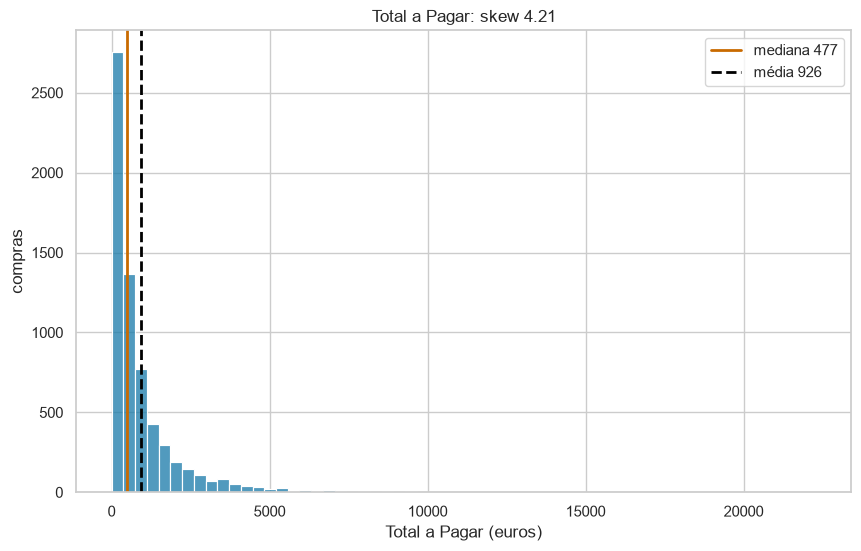

In [14]:
# Passo 8 - histograma de uma coluna monetária, com mediana e média
fig, ax = plt.subplots(figsize=FIGSIZE)
sns.histplot(raw["Total a Pagar"].dropna(), bins=60, color=PLOT_BLUE, ax=ax)
ax.axvline(raw["Total a Pagar"].median(), color=PLOT_ORANGE, lw=2,
           label=f"mediana {raw['Total a Pagar'].median():.0f}")
ax.axvline(raw["Total a Pagar"].mean(), color="black", lw=2, ls="--",
           label=f"média {raw['Total a Pagar'].mean():.0f}")
ax.set(xlabel="Total a Pagar (euros)", ylabel="compras",
       title=f"Total a Pagar: skew {raw['Total a Pagar'].skew():.2f}")
ax.legend()
plt.show()

In [15]:
# Passo 9 - valores fora do domínio: negativos e o valor 1e9
non_negative = [c for c in numeric if c != "random_noise"]
negative_rows = (raw[non_negative] < 0).sum()
for column in negative_rows[negative_rows > 0].index:
    print(f"{column:30s} min {raw[column].min():12.1f}   linhas negativas"
          f" {negative_rows[column]:4d}")

for column in ["days_since_previous_purchase", "prior_mean_gap_days"]:
    print(f"\n{column}:",
          raw.loc[raw[column] < 0, column].value_counts().to_dict())

placeholder_rows = (raw[numeric] == 1e9).sum()
print("\nlinhas com exatamente 1e9:",
      placeholder_rows[placeholder_rows > 0].to_dict())
for column in placeholder_rows[placeholder_rows > 0].index:
    print(f"maior valor de {column} sem essas linhas:"
          f" {raw.loc[raw[column] < 1e9, column].max():,.2f}")

days_since_previous_purchase   min         -4.0   linhas negativas   16
prior_mean_purchase_value      min      -2478.7   linhas negativas   16
prior_mean_gap_days            min         -4.0   linhas negativas   16
spend_365d                     min    -159115.2   linhas negativas   15

days_since_previous_purchase: {-4.0: 16}

prior_mean_gap_days: {-4.0: 16}

linhas com exatamente 1e9: {'prior_mean_purchase_value': 16, 'spend_365d': 15}
maior valor de prior_mean_purchase_value sem essas linhas: 72,937.16
maior valor de spend_365d sem essas linhas: 522,933.21


In [16]:
# Passo 10 - coerência entre colunas (sem as 65 linhas vazias; margem de 2 cêntimos)
complete = raw[~empty_rows]

checks = pd.Series({
    "Total a Pagar != Total Liquido + Total Imp_":
        ((complete["Total a Pagar"] - complete["Total Liquido"]
          - complete["Total Imp_"]).abs() > 0.02).sum(),
    "Total Liquido != Total Bruto - Desc_ Linha - Desc_ Global":
        ((complete["Total Liquido"] - complete["Total Bruto"]
          + complete["Total Desc_ Linha"] + complete["Total Desc_ Global"]).abs() > 0.02).sum(),
    "contagens em janela que não crescem (30d <= 90d <= 180d <= 365d)":
        ((complete["purchase_count_30d"] > complete["purchase_count_90d"])
         | (complete["purchase_count_90d"] > complete["purchase_count_180d"])
         | (complete["purchase_count_180d"] > complete["purchase_count_365d"])).sum(),
    "purchase_count_365d > prior_purchase_count":
        (complete["purchase_count_365d"] > complete["prior_purchase_count"]).sum(),
    "spend_365d < spend_180d":
        (complete["spend_365d"] < complete["spend_180d"] - 0.02).sum(),
    "prior_min_purchase_value > prior_max_purchase_value":
        (complete["prior_min_purchase_value"] > complete["prior_max_purchase_value"]).sum(),
    "prior_mean_purchase_value fora de [prior_min, prior_max]":
        ((complete["prior_mean_purchase_value"] < complete["prior_min_purchase_value"] - 0.02)
         | (complete["prior_mean_purchase_value"] > complete["prior_max_purchase_value"] + 0.02)).sum(),
    "prior_mean_purchase_value != prior_total_spend / prior_purchase_count":
        ((complete["prior_mean_purchase_value"] - complete["prior_total_spend"]
          / complete["prior_purchase_count"]).abs() > 0.02).sum(),
    "Custo > Total Liquido":
        (complete["Custo"] > complete["Total Liquido"]).sum(),
})
print(checks.to_frame("linhas que falham").to_string())

                                                                       linhas que falham
Total a Pagar != Total Liquido + Total Imp_                                            0
Total Liquido != Total Bruto - Desc_ Linha - Desc_ Global                              0
contagens em janela que não crescem (30d <= 90d <= 180d <= 365d)                       0
purchase_count_365d > prior_purchase_count                                             0
spend_365d < spend_180d                                                               15
prior_min_purchase_value > prior_max_purchase_value                                    0
prior_mean_purchase_value fora de [prior_min, prior_max]                              77
prior_mean_purchase_value != prior_total_spend / prior_purchase_count                 78
Custo > Total Liquido                                                                 39


In [17]:
# Passo 11 - cópia em que os valores impossíveis passam a nulo (raw não é alterado)
invalid_errors = {
    "days_since_previous_purchase": lambda values: values < 0,
    "prior_mean_gap_days": lambda values: values < 0,
    "prior_mean_purchase_value": lambda values: (values < 0) | (values == 1e9),
    "spend_365d": lambda values: (values < 0) | (values == 1e9),
}

checked = raw.copy()
for column, is_invalid in invalid_errors.items():
    checked[column] = checked[column].mask(is_invalid(checked[column]))

# regra com duas colunas: uma média não pode ser maior do que o máximo
above_max = (checked["prior_mean_purchase_value"]
             > checked["prior_max_purchase_value"] + 0.02)
checked["prior_mean_purchase_value"] = checked["prior_mean_purchase_value"].mask(above_max)

print(f"médias acima do máximo, depois das regras de uma coluna: {above_max.sum()}")
print(f"células nulas: {raw.isna().sum().sum():,} -> {checked.isna().sum().sum():,}")
print("spend_365d < spend_180d, depois:",
      (checked["spend_365d"] < checked["spend_180d"] - 0.02).sum())
print("prior_mean != prior_total_spend / prior_purchase_count, depois:",
      ((checked["prior_mean_purchase_value"] - checked["prior_total_spend"]
        / checked["prior_purchase_count"]).abs() > 0.02).sum(), "\n")
print(checked[list(invalid_errors)].describe().T.round(2).to_string())

médias acima do máximo, depois das regras de uma coluna: 45
células nulas: 9,818 -> 9,957
spend_365d < spend_180d, depois: 0
prior_mean != prior_total_spend / prior_purchase_count, depois: 1 

                               count     mean       std   min     25%      50%      75%        max
days_since_previous_purchase  5657.0   101.83    165.84  1.00   17.00    57.00   119.00    3199.00
prior_mean_gap_days           5210.0    96.18    122.65  1.00   42.86    68.61   114.00    3199.00
prior_mean_purchase_value     5595.0   870.21    745.62  3.31  357.84   718.97  1078.22    6685.17
spend_365d                    6244.0  5777.74  13900.88  0.00  643.29  2426.60  7010.41  522933.21


In [18]:
# Passo 12 - fração de nulos no histórico, por número de compras anteriores
history = ["days_since_previous_purchase", "prior_mean_purchase_value",
           "prior_min_purchase_value", "prior_max_purchase_value",
           "prior_std_purchase_value", "prior_mean_gap_days", "prior_std_gap_days"]

print("linhas por número de compras anteriores:",
      complete["prior_purchase_count"].value_counts().sort_index().head(5).to_dict())
by_prior_count = complete[history].isna().groupby(complete["prior_purchase_count"]).mean()
print(by_prior_count.head(5).round(3).T.to_string())

linhas por número de compras anteriores: {0.0: 603, 1.0: 445, 2.0: 365, 3.0: 319, 4.0: 270}
prior_purchase_count          0.0    1.0    2.0    3.0    4.0
days_since_previous_purchase  1.0  0.043  0.055  0.056  0.026
prior_mean_purchase_value     1.0  0.045  0.030  0.044  0.041
prior_min_purchase_value      1.0  0.000  0.000  0.000  0.000
prior_max_purchase_value      1.0  0.000  0.000  0.000  0.000
prior_std_purchase_value      1.0  1.000  0.000  0.000  0.000
prior_mean_gap_days           1.0  1.000  0.058  0.053  0.026
prior_std_gap_days            1.0  1.000  1.000  0.000  0.000


In [19]:
# Passo 12 - os nulos das outras cinco colunas caem nas mesmas linhas?
scattered = ["payment_type", "salesperson", "warehouse", "transport_method", "spend_365d"]
print("nulos por linha nestas cinco colunas:",
      complete[scattered].isna().sum(axis=1).value_counts().sort_index().to_dict())

# taxa do alvo na primeira compra, nas restantes e nas linhas vazias
first_purchase = complete["prior_purchase_count"] == 0
print(f"\ntaxa do alvo na primeira compra: {complete.loc[first_purchase, target].mean():.4f}"
      f" ({first_purchase.sum()} linhas)")
print(f"taxa do alvo nas restantes:      {complete.loc[~first_purchase, target].mean():.4f}")
print(f"taxa do alvo nas 65 linhas vazias: {raw.loc[empty_rows, target].mean():.4f}")

nulos por linha nestas cinco colunas: {0: 5544, 1: 875, 2: 50}

taxa do alvo na primeira compra: 0.3333 (603 linhas)
taxa do alvo nas restantes:      0.5830
taxa do alvo nas 65 linhas vazias: 0.5077


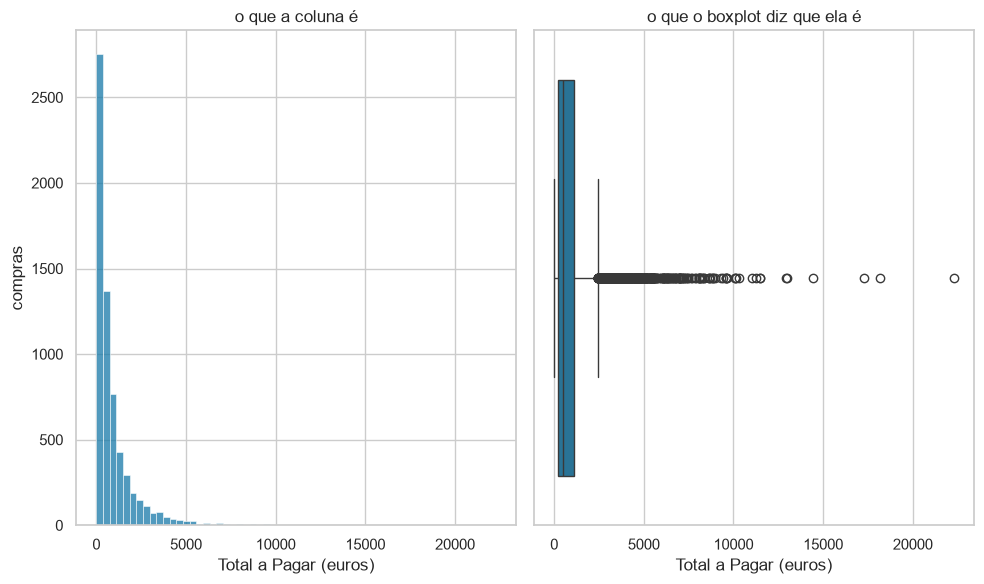

                        column      Q1       Q3  flagged  % flagged
                     spend_30d    0.00   338.24     1060      16.39
                  Total Portes    0.00     0.00     1053      16.28
             Total Desc_ Linha    0.00    92.28      822      12.71
      prior_min_purchase_value   15.45   162.61      671      11.44
           purchase_count_180d    1.00     3.00      737      11.39
                     spend_90d    0.00  1514.56      661      10.22
             prior_total_spend 1505.55 21642.32      642       9.92
                 Total a Pagar  188.92  1087.67      592       9.15
            prior_std_gap_days   32.74    78.63      461       9.12
                 Total Liquido  154.38   903.37      587       9.07
                   Total Bruto  175.74  1036.70      584       9.03
                         Custo   49.05   396.06      539       8.33
                    Total Imp_   29.93   184.84      533       8.24
           purchase_count_365d    1.00     7.00 

In [20]:
# Passo 13 - regra 1,5 x IQR: só para medir o que assinalaria (nada é removido)
fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE)
sns.histplot(checked["Total a Pagar"].dropna(), bins=60, color=PLOT_BLUE, ax=left)
left.set(xlabel="Total a Pagar (euros)", ylabel="compras", title="o que a coluna é")
sns.boxplot(x=checked["Total a Pagar"].dropna(), color=PLOT_BLUE, ax=right)
right.set(xlabel="Total a Pagar (euros)", title="o que o boxplot diz que ela é")
plt.tight_layout()
plt.show()

rows = []
for column in numeric:
    values = checked[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    flagged = (~values.between(q1 - 1.5 * iqr, q3 + 1.5 * iqr)).sum()
    rows.append({"column": column, "Q1": q1, "Q3": q3, "flagged": flagged,
                 "% flagged": 100 * flagged / len(values)})
fences = pd.DataFrame(rows).sort_values("% flagged", ascending=False)
print(fences.round(2).to_string(index=False))

In [21]:
# Passo 14 - linhas e taxa do alvo por nível de cada categórica (10 maiores níveis)
base_rate = raw[target].mean()
for column in categorical:
    by_level = pd.DataFrame({"linhas": raw.groupby(column).size(),
                             "taxa do alvo": raw.groupby(column)[target].mean()})
    print(f"{column}: {len(by_level)} níveis, {(by_level['linhas'] < 30).sum()}"
          f" com menos de 30 linhas")
    print(by_level.nlargest(10, "linhas").round(3).to_string(), "\n")

payment_type: 9 níveis, 4 com menos de 30 linhas
                           linhas  taxa do alvo
payment_type                                   
Maybe Tomorrow Payment 7     4565         0.527
Maybe Tomorrow Payment 12     991         0.543
Maybe Tomorrow Payment 9      502         0.950
Maybe Tomorrow Payment 10     134         0.403
Maybe Tomorrow Payment 8       40         0.325
Maybe Tomorrow Payment 2       21         0.524
Maybe Tomorrow Payment 4        9         0.444
Maybe Tomorrow Payment 11       8         0.625
Maybe Tomorrow Payment 3        4         0.500 

salesperson: 9 níveis, 3 com menos de 30 linhas
                  linhas  taxa do alvo
salesperson                           
VLOOKUP Master 1    4054         0.624
VLOOKUP Master 4    1461         0.394
VLOOKUP Master 9     384         0.547
VLOOKUP Master 7     201         0.483
VLOOKUP Master 2     123         0.602
VLOOKUP Master 3      30         0.367
VLOOKUP Master 6      12         0.000
VLOOKUP Master 5      

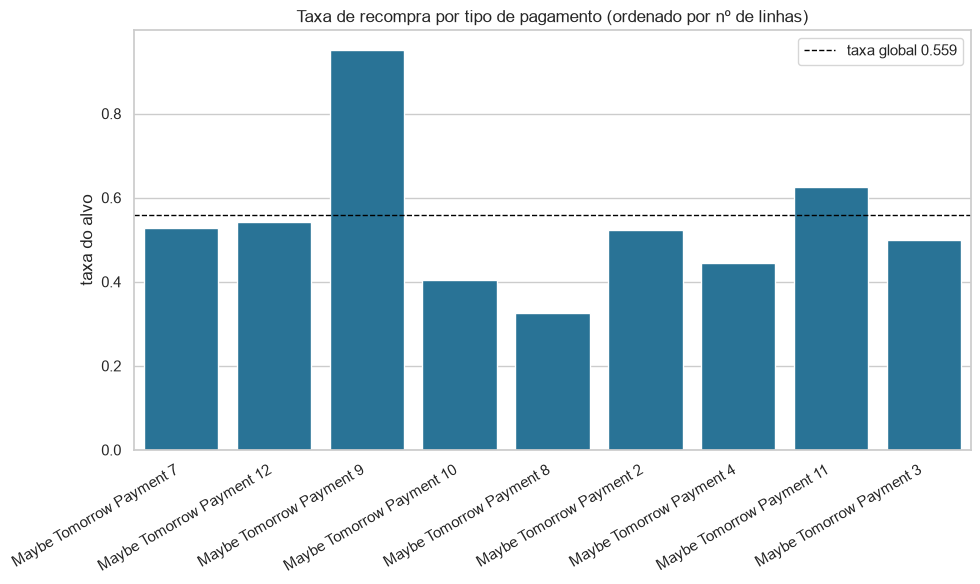

In [22]:
# Passo 14 - taxa do alvo por tipo de pagamento, contra a taxa global
payment = pd.DataFrame({"linhas": raw.groupby("payment_type").size(),
                        "taxa do alvo": raw.groupby("payment_type")[target].mean()})
payment = payment.sort_values("linhas", ascending=False).reset_index()

fig, ax = plt.subplots(figsize=FIGSIZE)
sns.barplot(payment, x="payment_type", y="taxa do alvo", color=PLOT_BLUE, ax=ax)
ax.axhline(base_rate, color="black", ls="--", lw=1,
           label=f"taxa global {base_rate:.3f}")
ax.set(xlabel="", ylabel="taxa do alvo",
       title="Taxa de recompra por tipo de pagamento (ordenado por nº de linhas)")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
ax.legend()
plt.tight_layout()
plt.show()

In [23]:
# Passo 15 - associação de cada categórica com o alvo: qui-quadrado e V de Cramér
def cramers_v(column, outcome):
    """Devolve qui-quadrado, valor-p, V de Cramér e a menor contagem esperada."""
    table = pd.crosstab(column, outcome)
    if min(table.shape) < 2:
        # um só nível presente: não há associação para medir
        return 0.0, float("nan"), 0.0, float(table.to_numpy().min())
    statistic, p, _, expected = chi2_contingency(table, correction=False)
    v = np.sqrt(statistic / (table.to_numpy().sum() * (min(table.shape) - 1)))
    return statistic, p, v, expected.min()


table = []
for column in categorical:
    statistic, p, v, expected = cramers_v(raw[column], raw[target])
    table.append({"column": column, "levels": raw[column].nunique(),
                  "chi2": statistic, "p": p, "Cramer's V": v,
                  "min expected": expected})
categorical_scores = pd.DataFrame(table).sort_values("Cramer's V", ascending=False)
print(categorical_scores.round(4).to_string(index=False))

          column  levels     chi2      p  Cramer's V  min expected
transport_method      80 527.2326 0.0000      0.2899        0.4400
    payment_type       9 354.3140 0.0000      0.2376        1.7616
     salesperson       9 259.4296 0.0000      0.2033        1.3243
 commercial_zone       5  26.2955 0.0000      0.0638        0.4403
       warehouse       2   5.4299 0.0198      0.0294        9.2950
 document_series       3   0.0553 0.9727      0.0029      804.7834


In [24]:
# Passo 16 - numéricas: mediana por classe e correlação ponto-bisserial com o alvo
medians = checked.groupby(target)[numeric].median()

# o ponto-bisserial não aceita nulos: cada coluna usa as linhas em que está preenchida
r_checked, r_raw = {}, {}
for column in numeric:
    pair = checked[[column, target]].dropna()
    r_checked[column] = pointbiserialr(pair[target], pair[column]).statistic
    pair = raw[[column, target]].dropna()
    r_raw[column] = pointbiserialr(pair[target], pair[column]).statistic

numeric_scores = pd.DataFrame({"mediana, alvo 0": medians.loc[0],
                               "mediana, alvo 1": medians.loc[1],
                               "r": r_checked,
                               "r_com_invalidos": r_raw})
numeric_scores["|r|"] = numeric_scores["r"].abs()
numeric_scores = numeric_scores.sort_values("|r|", ascending=False)
print(numeric_scores.round(3).to_string())

                                mediana, alvo 0  mediana, alvo 1      r  r_com_invalidos    |r|
purchase_count_365d                       2.000            5.000  0.340            0.340  0.340
purchase_count_180d                       1.000            3.000  0.334            0.334  0.334
purchase_count_90d                        0.000            1.000  0.328            0.328  0.328
spend_180d                              457.870         2106.220  0.301            0.301  0.301
prior_purchase_count                      6.000           17.000  0.299            0.299  0.299
spend_90d                                 0.000          746.190  0.269            0.269  0.269
purchase_count_30d                        0.000            0.000  0.263            0.263  0.263
prior_total_spend                      3246.525        12098.990  0.262            0.262  0.262
prior_mean_gap_days                     101.750           55.758 -0.239           -0.238  0.239
prior_std_gap_days                      

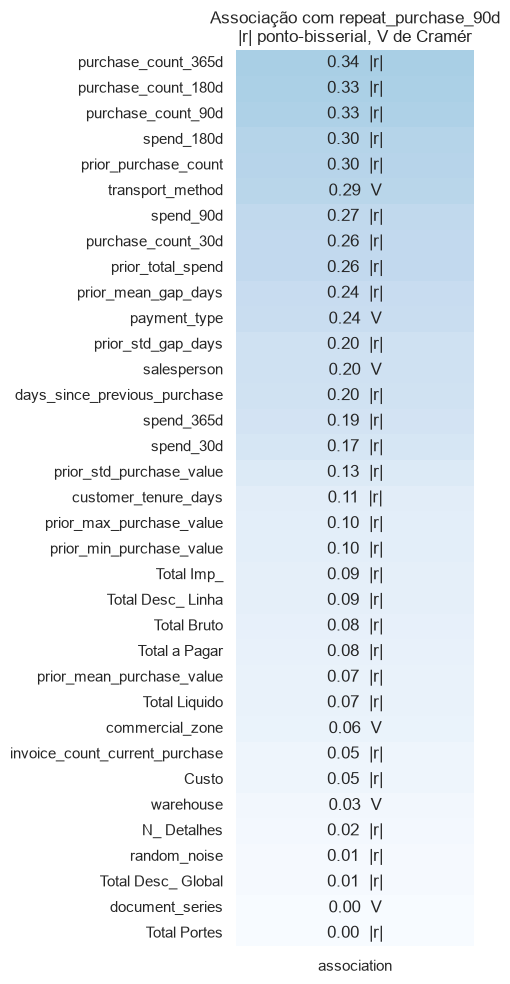

In [25]:
# Passo 17 - |r| das numéricas e V das categóricas na mesma ordenação
source_scores = pd.concat([
    numeric_scores["|r|"],
    categorical_scores.set_index("column")["Cramer's V"],
]).sort_values(ascending=False)

relevance_view = source_scores.to_frame("association")
relevance_labels = [[f"{value:.2f}  {'|r|' if name in numeric else 'V'}"]
                    for name, value in relevance_view["association"].items()]
fig, ax = plt.subplots(figsize=(5, 10))
sns.heatmap(relevance_view, annot=relevance_labels, fmt="", cmap="Blues",
            vmin=0, vmax=1, cbar=False, ax=ax)
ax.set(title="Associação com repeat_purchase_90d\n|r| ponto-bisserial, V de Cramér",
       xlabel="", ylabel="")
fig.tight_layout()
plt.show()

In [26]:
# Passo 18 - pares de numéricas com correlação acima de 0,70
REDUNDANT = 0.70

between = checked[numeric].corr().abs()
pairs_above = [
    (numeric[i], numeric[j], between.iloc[i, j])
    for i, j in zip(*np.triu_indices_from(between, 1))
    if between.iloc[i, j] > REDUNDANT
]
print(f"pares acima de {REDUNDANT}: {len(pairs_above)} de"
      f" {len(numeric) * (len(numeric) - 1) // 2}")
for left, right, value in sorted(pairs_above, key=lambda row: -row[2]):
    print(f"  {left:32s} {right:32s} {value:.3f}")

pares acima de 0.7: 23 de 406
  Total a Pagar                    Total Liquido                    0.996
  Total Bruto                      Total Liquido                    0.984
  Total a Pagar                    Total Bruto                      0.975
  purchase_count_180d              purchase_count_365d              0.954
  purchase_count_90d               purchase_count_180d              0.935
  Total a Pagar                    Total Imp_                       0.901
  purchase_count_90d               purchase_count_365d              0.883
  prior_mean_purchase_value        prior_std_purchase_value         0.878
  prior_mean_gap_days              prior_std_gap_days               0.872
  Total Liquido                    Total Imp_                       0.860
  spend_90d                        spend_180d                       0.856
  purchase_count_30d               purchase_count_90d               0.845
  Total a Pagar                    Custo                            0.819
  Total 

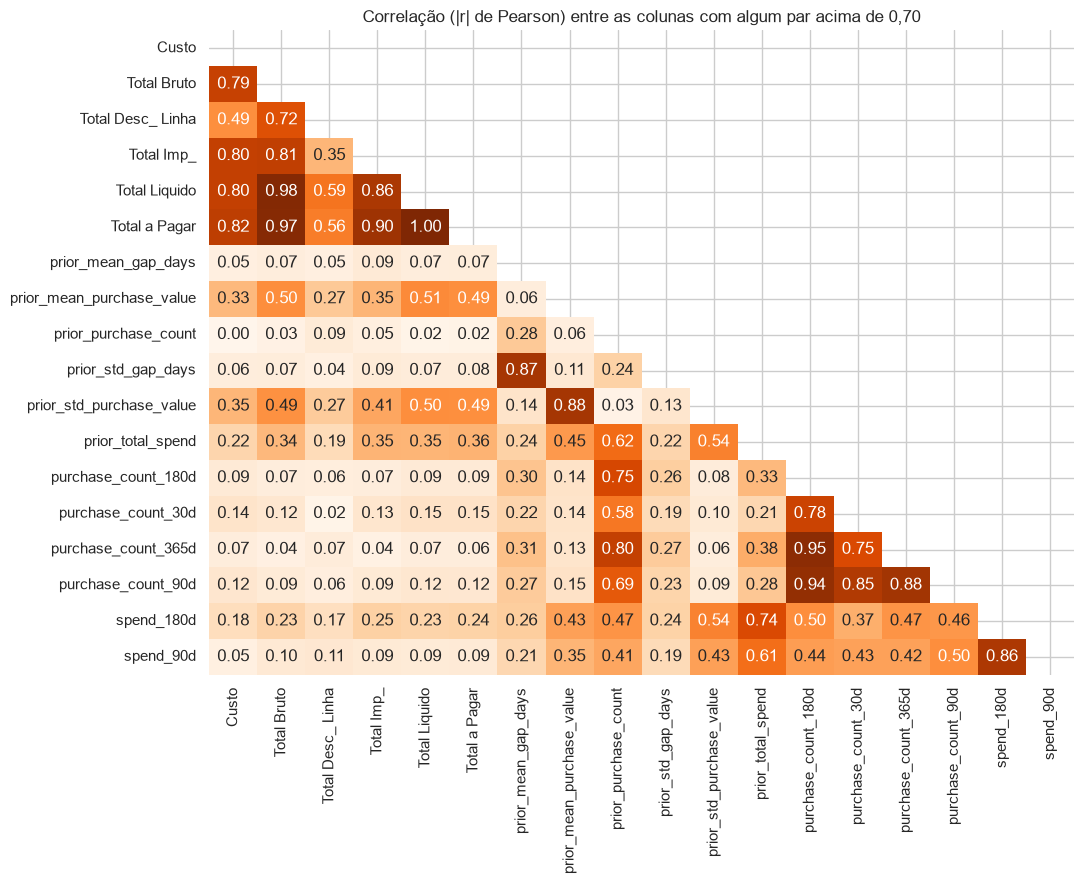

In [27]:
# Passo 18 - heatmap das colunas que entram em algum par redundante
redundant_names = sorted({name for left, right, _ in pairs_above
                          for name in (left, right)})
redundancy_view = between.loc[redundant_names, redundant_names]
mask = np.triu(np.ones_like(redundancy_view, dtype=bool))  # esconde o triângulo de cima
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(redundancy_view, mask=mask, annot=True, fmt=".2f",
            cmap="Oranges", vmin=0, vmax=1, cbar=False, ax=ax)
ax.set(title="Correlação (|r| de Pearson) entre as colunas com algum par acima de 0,70",
       xlabel="", ylabel="")
fig.tight_layout()
plt.show()

count    6469.000
mean       -0.022
std         1.001
min        -3.529
25%        -0.678
50%        -0.046
75%         0.642
max         4.151

skew: 0.054
r ponto-bisserial com o alvo: -0.0120
maior |r| com outra coluna numérica: 0.0288


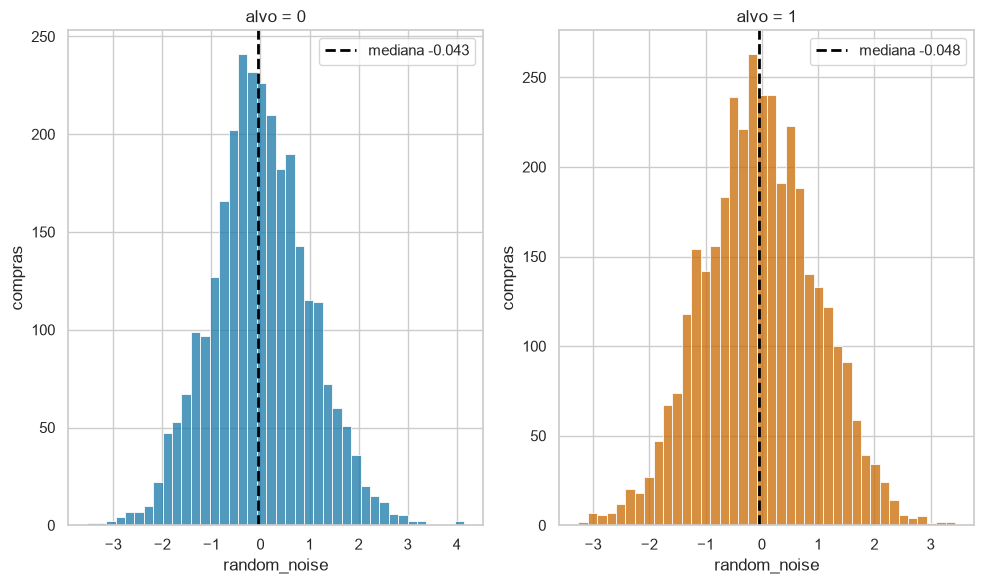

In [28]:
# Passo 19 - random_noise: resumo, relação com o alvo e com as outras colunas
print(raw["random_noise"].describe().round(3).to_string())
print(f"\nskew: {raw['random_noise'].skew():.3f}")
print(f"r ponto-bisserial com o alvo: {numeric_scores.loc['random_noise', 'r']:.4f}")
print(f"maior |r| com outra coluna numérica:"
      f" {between['random_noise'].drop('random_noise').max():.4f}")

noise_0 = raw.loc[raw[target] == 0, "random_noise"].dropna()
noise_1 = raw.loc[raw[target] == 1, "random_noise"].dropna()

fig, (left, right) = plt.subplots(1, 2, figsize=FIGSIZE)
sns.histplot(noise_0, bins=40, color=PLOT_BLUE, ax=left)
left.axvline(noise_0.median(), color="black", lw=2, ls="--",
             label=f"mediana {noise_0.median():.3f}")
left.set(xlabel="random_noise", ylabel="compras", title="alvo = 0")
left.legend()
sns.histplot(noise_1, bins=40, color=PLOT_ORANGE, ax=right)
right.axvline(noise_1.median(), color="black", lw=2, ls="--",
              label=f"mediana {noise_1.median():.3f}")
right.set(xlabel="random_noise", ylabel="compras", title="alvo = 1")
right.legend()
plt.tight_layout()
plt.show()

In [29]:
# Passo 20 - intervalo de datas (formato AAAA-MM-DD: ordem do texto = ordem do calendário)
print("primeira compra:", raw["purchase_date"].dropna().min())
print("última compra:  ", raw["purchase_date"].dropna().max())
print("datas distintas:", raw["purchase_date"].nunique(),
      "| nulos:", raw["purchase_date"].isna().sum())

primeira compra: 2015-07-11
última compra:   2025-02-15
datas distintas: 1492 | nulos: 65


In [30]:
# Passo 21 - clientes.csv: cobertura dos clientes do treino, nulos e níveis por coluna
clientes = pd.read_csv("../data/clientes.csv", index_col="customer_id")
print(f"{clientes.shape[0]:,} linhas x {clientes.shape[1]} colunas,"
      f" {clientes.index.nunique():,} customer_id distintos")

print(f"linhas do treino cujo cliente está em clientes.csv:"
      f" {100 * raw['customer_id'].isin(clientes.index).mean():.2f}%")
in_train = clientes[clientes.index.isin(raw["customer_id"])]
print(f"clientes de clientes.csv que aparecem no treino:"
      f" {len(in_train)} de {len(clientes)}\n")

in_train.info()
pd.DataFrame({"% nulos": (100 * in_train.isna().mean()).round(1),
              "níveis": in_train.nunique()})

1,143 linhas x 12 colunas, 1,143 customer_id distintos
linhas do treino cujo cliente está em clientes.csv: 100.00%
clientes de clientes.csv que aparecem no treino: 610 de 1143

<class 'pandas.DataFrame'>
Index: 610 entries, 770941 to 994493
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   country_or_region    610 non-null    str    
 1   commercial_region    598 non-null    str    
 2   island               324 non-null    str    
 3   municipality         569 non-null    str    
 4   city                 374 non-null    str    
 5   postal_area          570 non-null    str    
 6   postal_code          590 non-null    str    
 7   street               280 non-null    str    
 8   address              610 non-null    str    
 9   customer_type        0 non-null      float64
 10  company_name         610 non-null    str    
 11  customer_since_year  610 non-null    int64  
dtypes: float64(1), int64(

,% nulos,níveis
country_or_region,0.0,7
commercial_region,2.0,32
island,46.9,10
municipality,6.7,150
city,38.7,260
postal_area,6.6,189
postal_code,3.3,519
street,54.1,266
address,0.0,600
customer_type,100.0,0
